<a href="https://colab.research.google.com/github/VadymChubLabs/IAD/blob/main/Lab2_Raisin_Text.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №2
## Зниження розмірності, кластеризація та класифікація текстових даних

**Мета:** застосувати PCA і t-SNE до Raisin із Lab 1, виконати K-Means та класифікувати тексти SMS.

**Набори даних:** [Raisin — UCI](https://archive.ics.uci.edu/dataset/850/raisin) та
[SMS Spam Collection — UCI](https://archive.ics.uci.edu/dataset/228/sms+spam+collection).

SMS — обраний текстовий датасет для третього завдання.



In [1]:
%pip install -q wordcloud openpyxl

In [2]:
import io
import re
import html
import zipfile
from urllib.request import urlopen
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, silhouette_score, adjusted_rand_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.svm import LinearSVC

RANDOM_STATE = 42

## 1. Завантаження Raisin

Використовуємо той самий датасет, що й у Lab 1: 900 родзинок, 7 числових ознак,
два сорти — `Besni` та `Kecimen`. Відокремлюємо цільову змінну `Class` від ознак.
Перевіряємо розмір, пропуски та баланс класів.

In [3]:
with urlopen("https://archive.ics.uci.edu/static/public/850/raisin.zip", timeout=90) as response:
    archive = zipfile.ZipFile(io.BytesIO(response.read()))
inner = zipfile.ZipFile(io.BytesIO(archive.read("Raisin_Dataset.zip")))
excel = next(name for name in inner.namelist() if name.endswith(".xlsx"))
df = pd.read_excel(io.BytesIO(inner.read(excel)))
X, y = df.drop(columns="Class"), df["Class"]

display(df.head())
print("Розмір:", X.shape, "Пропуски:", df.isna().sum().sum())
print(y.value_counts())

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


Розмір: (900, 7) Пропуски: 0
Class
Kecimen    450
Besni      450
Name: count, dtype: int64


## 2. PCA: класифікація до та після зниження розмірності

Ділимо дані на 80% train та 20% test, як у Lab 1. `stratify=y` зберігає співвідношення класів.
`StandardScaler` приводить ознаки до порівнянного масштабу, щоб площа не домінувала над іншими характеристиками.

Порівнюємо **kNN із k=16** без PCA та з PCA, що зберігає щонайменше **95% дисперсії**.
PCA створює нові ознаки — лінійні комбінації початкових. Вона не використовує класи,
тому збережена дисперсія не дорівнює точності класифікації.

`make_pipeline` об'єднує етапи: масштабування і PCA навчаються лише на train.
Обидва варіанти перевіряємо на одному test. Час `fit` усього ланцюжка усереднюємо
за 5 повторів; він залежить від комп'ютера та навантаження.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
models = {
    "kNN без PCA": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=16)),
    "kNN + PCA": make_pipeline(StandardScaler(), PCA(n_components=0.95),
                               KNeighborsClassifier(n_neighbors=16))
}
rows = []
for name, model in models.items():
    times = []
    for _ in range(5):
        start = perf_counter()
        model.fit(X_train, y_train)
        times.append((perf_counter() - start) * 1000)
    prediction = model.predict(X_test)
    features = model.named_steps["pca"].n_components_ if "pca" in model.named_steps else X.shape[1]
    rows.append({"Модель": name, "Ознак": features,
                 "Accuracy": accuracy_score(y_test, prediction), "Fit, мс": np.mean(times)})

pca_results = pd.DataFrame(rows)
display(pca_results.round(4))
pca = models["kNN + PCA"].named_steps["pca"]
print(f"Збережена дисперсія: {pca.explained_variance_ratio_.sum():.2%}")

,Модель,Ознак,Accuracy,"Fit, мс"
0,kNN без PCA,7,0.8833,16.8790
1,kNN + PCA,3,0.8833,18.3379


Збережена дисперсія: 98.75%


**Висновок щодо PCA:** кількість ознак зменшено з 7 до 3, збережено 98.75% дисперсії. Accuracy до PCA — 0.8833, після — 0.8833. Середній час навчання всього ланцюжка: 3.801 мс та 4.995 мс відповідно. Додавання PCA потребує обчислень, тому стиснення ознак не гарантує швидшого навчання. Час може змінюватися при повторному запуску.

## 3. t-SNE: візуалізація у 2D

Для описового аналізу масштабуємо всі дані та перетворюємо їх на дві координати.
Ця окрема візуалізація не впливає на попереднє тестування класифікатора.
Мітки використовуємо лише для кольору точок. t-SNE показує локальне сусідство;
осі не мають фізичного змісту, а відстані між віддаленими групами не слід трактувати буквально.

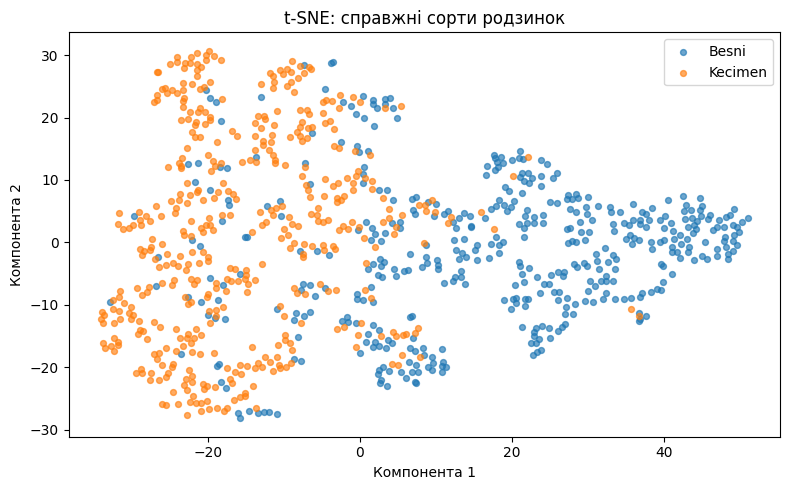

In [5]:
X_scaled = StandardScaler().fit_transform(X)
tsne = TSNE(n_components=2, perplexity=30, init="pca",
            learning_rate="auto", random_state=RANDOM_STATE)
Z_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
for label in sorted(y.unique()):
    mask = y == label
    plt.scatter(Z_tsne[mask, 0], Z_tsne[mask, 1], label=label, s=18, alpha=0.65)
plt.title("t-SNE: справжні сорти родзинок")
plt.xlabel("Компонента 1")
plt.ylabel("Компонента 2")
plt.legend()
plt.tight_layout()
plt.show()

**Висновок:** на проєкції є області з переважанням окремих сортів, але між ними
спостерігаються змішані ділянки. Геометричні характеристики класів частково перекриваються.
Видимі групи на t-SNE самі по собі не доводять наявності окремих кластерів.

## 4. K-Means: кластеризація без міток класів

Навчаємо K-Means на всіх 7 масштабованих ознаках **без `y`**.
Перевіряємо від 2 до 10 кластерів; `n_init=20` задає 20 початкових ініціалізацій.
Обираємо `k` за найбільшим **silhouette score**: він оцінює близькість об'єктів
усередині кластерів і віддаленість між кластерами, має значення від −1 до 1.
За умовою достатньо silhouette або elbow method; тут використовуємо silhouette.

Обрано k=2; silhouette=0.4411


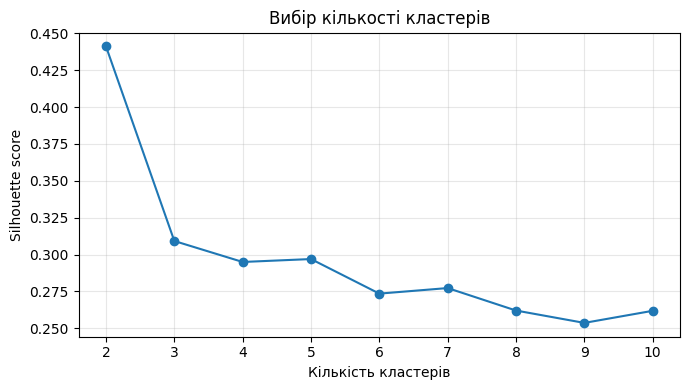

In [6]:
scores = []
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled)
    scores.append(silhouette_score(X_scaled, labels))

best_k = int(np.argmax(scores) + 2)
clusters = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled)
print(f"Обрано k={best_k}; silhouette={max(scores):.4f}")
plt.figure(figsize=(7, 4))
plt.plot(range(2, 11), scores, "o-")
plt.xticks(range(2, 11))
plt.xlabel("Кількість кластерів")
plt.ylabel("Silhouette score")
plt.title("Вибір кількості кластерів")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Порівняння кластерів зі справжніми класами

Проєктуємо дані на 2 компоненти PCA лише для графіка. K-Means уже навчений у 7D.
Справжні мітки використовуємо тепер — для порівняння та інтерпретації.
**ARI** оцінює збіг поділів незалежно від номерів кластерів: 1 — повний збіг,
близько 0 — відповідність на рівні випадкового поділу. Кластер 0 не означає автоматично `Besni`.

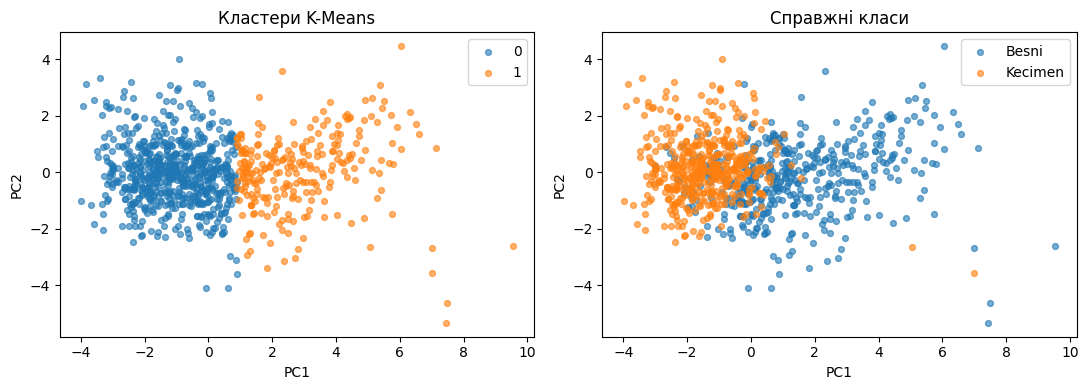

Class,Besni,Kecimen
Кластер,,
0,204,445
1,246,5


ARI: 0.2862


In [7]:
Z_pca = PCA(n_components=2).fit_transform(X_scaled)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, labels, title in [(axes[0], clusters, "Кластери K-Means"),
                           (axes[1], y.to_numpy(), "Справжні класи")]:
    for label in sorted(set(labels)):
        mask = labels == label
        ax.scatter(Z_pca[mask, 0], Z_pca[mask, 1], label=str(label), s=18, alpha=0.6)
    ax.set(title=title, xlabel="PC1", ylabel="PC2")
    ax.legend()
plt.tight_layout()
plt.show()

cluster_table = pd.crosstab(pd.Series(clusters, name="Кластер"), y)
display(cluster_table)
ari = adjusted_rand_score(y, clusters)
print(f"ARI: {ari:.4f}")

**Висновок:** обрано 2 кластери, silhouette = 0.4411, ARI = 0.2862. Один кластер містить переважно Besni, а інший змішує обидва сорти. Отже, кластери лише частково відповідають класам: K-Means групує об’єкти за близькістю ознак, а не за назвами сортів.

## 5. Класифікація текстів SMS
### Завантаження та очищення

У третьому завданні потрібен **окремий текстовий датасет**. Обрано SMS Spam Collection:
`ham` — звичайні повідомлення, `spam` — спам. Читаємо мітку й текст, розділені табуляцією.

Декодуємо HTML-позначення, переводимо текст у нижній регістр, прибираємо числа,
пунктуацію й англійські стоп-слова. Прибираємо порожні тексти, суперечливі мітки
та дублікати очищених повідомлень до поділу, щоб однакові тексти не потрапили і в train, і в test.

In [8]:
with urlopen("https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip", timeout=90) as response:
    archive = zipfile.ZipFile(io.BytesIO(response.read()))
lines = archive.read("SMSSpamCollection").decode("utf-8-sig").splitlines()
sms = pd.DataFrame([line.split("\t", 1) for line in lines if line.strip()], columns=["label", "text"])

def clean_text(text):
    words = re.findall(r"[a-z]{2,}", html.unescape(text).lower())
    return " ".join(word for word in words if word not in ENGLISH_STOP_WORDS | {"ll", "ve", "re"})

sms["clean"] = sms["text"].map(clean_text)
sms = sms[sms["clean"] != ""]
consistent = sms.groupby("clean")["label"].transform("nunique") == 1
sms = sms[consistent].drop_duplicates("clean")
print("Після очищення:", len(sms))
print(sms["label"].value_counts())
display(sms[["text", "clean"]].head())

Після очищення: 5015
label
ham     4441
spam     574
Name: count, dtype: int64


,text,clean
0,"Go until jurong point, crazy.. Available only ...",jurong point crazy available bugis great world...
1,Ok lar... Joking wif u oni...,ok lar joking wif oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,dun say early hor say
4,"Nah I don't think he goes to usf, he lives aro...",nah don think goes usf lives


### TF-IDF та WordCloud

Стратифіковано ділимо повідомлення на 80% train та 20% test.
**TF-IDF** перетворює слова й пари слів на числові ваги: поширені в багатьох
повідомленнях терміни мають меншу інформативність. Словник та IDF навчаються лише на train.

Для WordCloud обчислюємо середню TF-IDF-вагу термінів у кожному навчальному класі:
більший напис означає більшу середню вагу. Це помітні терміни класу, але не обов'язково унікальні для нього.

Train: (4012, 4852) Test: (1003, 4852)


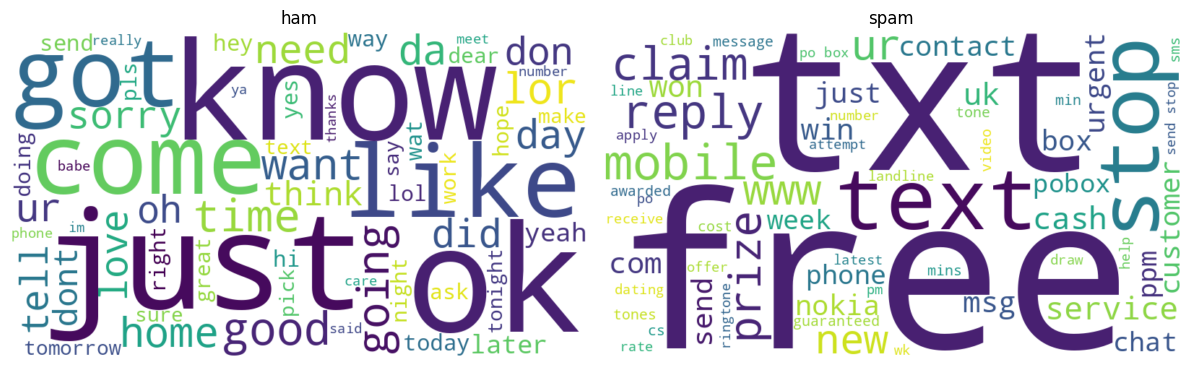

In [9]:
text_train, text_test, label_train, label_test = train_test_split(
    sms["clean"], sms["label"], test_size=0.2, stratify=sms["label"], random_state=RANDOM_STATE
)
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=10000, sublinear_tf=True)
train_tfidf = vectorizer.fit_transform(text_train)
test_tfidf = vectorizer.transform(text_test)
print("Train:", train_tfidf.shape, "Test:", test_tfidf.shape)

terms = vectorizer.get_feature_names_out()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, label in zip(axes, ["ham", "spam"]):
    weights = np.asarray(train_tfidf[label_train.to_numpy() == label].mean(axis=0)).ravel()
    frequencies = dict(zip(terms[weights > 0], weights[weights > 0]))
    cloud = WordCloud(width=800, height=450, background_color="white", max_words=60,
                      random_state=RANDOM_STATE).generate_from_frequencies(frequencies)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Інтерпретація:** у звичайних SMS помітні `ok`, `know`, `come`, `like` — слова
повсякденного листування. У спамі виділяються `free`, `txt`, `mobile`, `reply` —
лексика пропозицій та закликів відповісти. Одне слово саме по собі не визначає клас.

### Навчання та оцінювання

Використовуємо **LinearSVC** — лінійний SVM для розріджених текстових ознак.
`class_weight="balanced"` враховує меншу кількість спаму.
Крім accuracy, дивимося **precision** (частка правильних серед передбачень класу),
**recall** (частка знайдених серед реальних об'єктів класу) та **F1** (їх гармонійне середнє).
У матриці помилок рядки — справжні класи, стовпці — передбачення.

Accuracy: 0.9801
              precision    recall  f1-score   support

         ham     0.9865    0.9910    0.9888       888
        spam     0.9279    0.8957    0.9115       115

    accuracy                         0.9801      1003
   macro avg     0.9572    0.9433    0.9501      1003
weighted avg     0.9798    0.9801    0.9799      1003



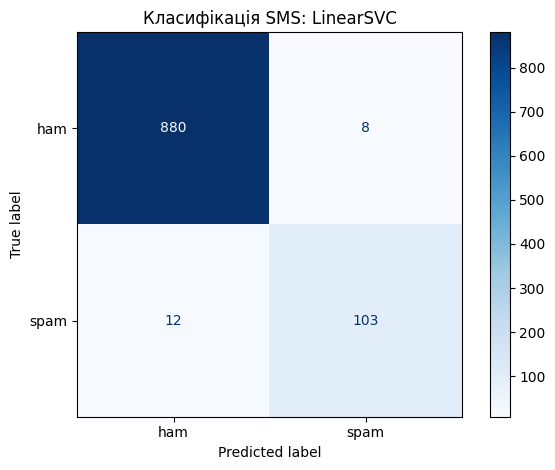

In [10]:
text_model = LinearSVC(class_weight="balanced", random_state=RANDOM_STATE, max_iter=10000)
text_model.fit(train_tfidf, label_train)
text_pred = text_model.predict(test_tfidf)
print(f"Accuracy: {accuracy_score(label_test, text_pred):.4f}")
print(classification_report(label_test, text_pred, digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(label_test, text_pred, labels=["ham", "spam"], cmap="Blues")
plt.title("Класифікація SMS: LinearSVC")
plt.tight_layout()
plt.show()

**Висновок:** accuracy = 0.9801, F1 для spam = 0.9115. Модель помилково позначила спамом 8 звичайних повідомлень і пропустила 12 спам-повідомлень. Висока accuracy не означає відсутності помилок; потрібно окремо оцінювати менш численний клас spam. Очищення спрощує тексти, але також прибирає потенційно корисні сигнали — числа та пунктуацію.

## Загальний висновок

PCA дозволила зменшити розмірність Raisin зі збереженням тестової точності kNN.
t-SNE показала часткове перекриття сортів. K-Means знайшов групи без використання
міток, однак їхній склад не повністю відповідає реальним класам.

Для текстів виконано очищення, WordCloud, TF-IDF та класифікацію SVM.
При дисбалансі класів потрібно оцінювати не лише accuracy, а й precision, recall та F1
для спаму. Результати стосуються одного фіксованого розбиття даних; вони не доводять
універсальної переваги методу на інших наборах.